In [58]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import convolve2d
from pathlib import Path
from progressbar import progressbar
from scipy.signal import butter, filtfilt, firwin


start_scope()

DATA_PATH = Path('data') 
TRAIN_IMG_PATH = DATA_PATH / 'train_images_diag'
defaultclock.dt = 100 * us

alcohol=0
n_rc=14
n_input_rows = n_rc-2  
n_input_columns = n_rc-2  
n_output_rows = n_rc-4  
n_output_columns = n_rc-4  
N_inp = n_input_rows*n_input_columns
N_E = n_output_rows*n_output_columns
n_inh_rows, n_inh_cols = 5, 5
N_I = n_inh_rows * n_inh_cols

# Inhibitory neuron positions (scaled to excitatory grid)
inh_positions = []
for iy in range(n_inh_rows):
    for ix in range(n_inh_cols):
        # scale inhibitory coordinates to excitatory grid
        x = int((ix + 0.5) * n_output_columns / n_inh_cols)
        y = int((iy + 0.5) * n_output_rows / n_inh_rows)
        inh_positions.append((x, y))


# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -55. * mV
V_E = 0.0 * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.2 * nF

# membrane leak
g_m_E = 10. * nS
g_m_I = 15. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# AMPA
g_AMPA_ext_E = 5.5 * nS 
g_AMPA_rec_E = 5.5 * nS 
g_AMPA_ext_I = 5.5 * nS
g_AMPA_rec_I = 5.5 * nS 
tau_AMPA = 8. * ms


# GABAa
g_GABA_E = 1.0*nS 
g_GABA_I = 1.0*nS 
tau_GABA = 10. * ms

# external stimuli
rate = 3 * Hz
C_ext = 800


#STDP/iSTDP
Apre   =  0.0025
Apost  = -0.0030
w_max = 1.0 #1.5

Apre_i  = -0.0010
Apost_i =  0.0012
w_max_i = 1.0

#HSP
# tau_HSP = 20*second           
# alpha_HSP = 0.001            
# target_rate = 10*Hz
# tau_insert = 10 * second  
# tau_intern = 1 * second  

# tau_vm = 200*ms
# vm_record_dt = 10*ms

tau_HSP = 2000*second           #1
target_rate = 10*Hz            #0.8
record_dt = 200*ms

tau_vm = 10*second
tau_active = 10*second
  

# rf_indices = [1,25,33,46,53,64,77,85,96]
center_neurons = [14, 24,34, 44, 54, 64,89]
recurrent_radius = 3

# Alcohol effect strengths (fractions)
ALC_RED_AMPA_E = 0.1   # X% reduction of excitatory drive onto E
ALC_RED_AMPA_I = 0.5   # X% increase of excitatory drive onto I
ALC_INC_GABA_E = 0.2   # X% increase of inhibitory drive onto E
ALC_INC_GABA_I = 0.2   # X% decrease of inhibitory drive onto I



kill_mask = np.ones(144, dtype=np.float32)
#ind_mod = np.array([range(39,42),range(51,54),range(63,66)]).flatten() #4x4
#ind_mod = np.array([range(39,41),range(51,53),range(63,65)]).flatten() #3x3
ind_mod = np.array([range(39,40),range(51,52)]).flatten()
kill_mask[ind_mod]=0
#kill_mask = np.ones((n_input_rows, n_input_columns), dtype=np.float32)
# kill_mask[3, 3] = 0
# kill_mask[3, 4] = 0
# kill_mask[3, 5] = 0
# kill_mask[3, 6] = 0
# kill_mask[4, 3] = 0
# kill_mask[4, 4] = 0
# kill_mask[4, 5] = 0
# kill_mask[4, 6] = 0
# kill_mask[5, 3] = 0
# kill_mask[5, 4] = 0
# kill_mask[5, 5] = 0
# kill_mask[5, 6] = 0



def create_mexican_hat_kernel():
    from scipy.ndimage import gaussian_filter
    center = np.zeros((3,3))
    center[1,1] = 1.0
    g1 = gaussian_filter(center, sigma=0.5)
    g2 = gaussian_filter(center, sigma=1.0)
    return g1 - g2
kernel = create_mexican_hat_kernel() 


def apply_mexican_hat(img):
    filtered = convolve2d(img, kernel, mode='valid')  
    return filtered


def generate_bar_image(shape=(n_rc, n_rc), n_bars=3):
    img = np.zeros(shape, dtype=np.float32)
    #orientation = np.random.choice(['horizontal', 'vertical', 'diagonal'])
    orientation = 'diagonal'

    for _ in range(n_bars):
        if orientation == 'horizontal':
            row = np.random.randint(1, shape[0]-1)
            img[row, :] = 1.0
        elif orientation == 'vertical':
            col = np.random.randint(1, shape[1]-1)
            img[:, col] = 1.0
        elif orientation == 'diagonal':
            shift = np.random.randint(-shape[0]//2, shape[0]//2)
            for i in range(shape[0]):
                j = i + shift
                if 0 <= j < shape[1]:
                    img[i, j] = 1.0
    return img


def mexican_hat(img):
    filtered = convolve2d(img, kernel, mode='valid')  
    return filtered

def convert_to_rates(filtered_img, max_rate=60):
    filtered_img = abs(filtered_img)
    norm_img = filtered_img - np.min(filtered_img)
    norm_img /= np.max(norm_img)
    rates = norm_img.flatten() * max_rate
    rates = clip(rates,5,60) * Hz
    return rates

def load_npy(path):
    arr = np.load(path)
    print('Loading', path, arr.shape)
    return arr

def save_npy(arr, path):
    arr = np.array(arr)
    print('Saving', arr.shape, path)
    np.save(path, arr)


def build_network(training,alcohol,target_rate = 10*Hz):
    # variables
    n_input_rows = n_rc-2  
    n_input_columns = n_rc-2  
    n_output_rows = n_rc-4  
    n_output_columns = n_rc-4  
    N_inp = n_input_rows*n_input_columns
    N_E = n_output_rows*n_output_columns
    n_inh_rows, n_inh_cols = 5, 5
    N_I = n_inh_rows * n_inh_cols 

    # modeling
    eqs_E = '''
    dv / dt = (- g_m_E * (v - V_L) - I_syn ) / C_m_E : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp

    # Homeostatically scaled synaptic currents
    I_AMPA_ext = g_AMPA_ext_E * (1 - ALC_RED_AMPA_E * alc) * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_E * g_AMPA_E_hsp * (1 - ALC_RED_AMPA_E * alc) * (v - V_E) * s_AMPA : amp
    I_GABA_rec = g_GABA_E    * g_GABA_E_hsp * (1 + ALC_INC_GABA_E * alc) * (v - V_I) * s_GABA     : amp

    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt      = - s_AMPA / tau_AMPA     : 1
    ds_GABA / dt      = - s_GABA / tau_GABA     : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    # HSP scaling variables (dimensionless)
    dg_AMPA_E_hsp/dt = ((1 - g_AMPA_E_hsp) * clip((target_rate - r_est)/target_rate, 0, 1) / tau_ins_AMPA_E
                - (g_AMPA_E_hsp - 0.1) * clip((r_est - target_rate)/target_rate, 0, 1) / tau_int_AMPA_E) : 1

    dg_GABA_E_hsp/dt = (-(g_GABA_E_hsp - 0.1) * clip((target_rate - r_est)/target_rate, 0, 1) / tau_int_GABA_E
                + (1 - g_GABA_E_hsp) * clip((r_est - target_rate)/target_rate, 0, 1) / tau_ins_GABA_E) : 1

    dvm_lp / dt = (v - vm_lp)/tau_vm : volt
    dy_act / dt = -y_act / tau_active : 1

    alc = int(t >= t_on) * int(t < t_off) : 1
    t_on  : second (shared)
    t_off : second (shared)

    tau_ins_AMPA_E : second (shared)
    tau_int_AMPA_E : second (shared)
    tau_int_GABA_E : second (shared)
    tau_ins_GABA_E : second (shared)
    '''


    eqs_I = '''
    dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
    I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
    I_AMPA_ext = g_AMPA_ext_I * (1 - ALC_RED_AMPA_I * alc) * (v - V_E) * s_AMPA_ext : amp
    I_AMPA_rec = g_AMPA_rec_I * g_AMPA_I_hsp * (1 + ALC_RED_AMPA_I * alc) * (v - V_E) * 1 * s_AMPA : amp
    ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
    ds_AMPA / dt = - s_AMPA / tau_AMPA : 1

    I_GABA_rec = g_GABA_I * g_GABA_I_hsp * (1 + ALC_INC_GABA_I * alc) * (v - V_I) * s_GABA : amp
    ds_GABA / dt = - s_GABA / tau_GABA : 1

    dx_spike / dt = -x_spike/tau_HSP : 1
    r_est = x_spike / tau_HSP : Hz

    dg_AMPA_I_hsp/dt = ((1 - g_AMPA_I_hsp) * clip((-r_est +target_rate)/target_rate, 0, 1) / tau_ins_AMPA_I
                - (g_AMPA_I_hsp - 0.1) * clip((-target_rate + r_est)/target_rate, 0, 1) / tau_int_AMPA_I) : 1

    dg_GABA_I_hsp/dt = (-(g_GABA_I_hsp - 0.1) * clip((-r_est + target_rate)/target_rate, 0, 1) / tau_int_GABA_I
                + (1 - g_GABA_I_hsp) * clip((-target_rate + r_est)/target_rate, 0, 1) / tau_ins_GABA_I) : 1


    dy_act / dt = -y_act / tau_active : 1

    alc = int(t >= t_on) * int(t < t_off) : 1
    t_on  : second (shared)
    t_off : second (shared)

    tau_ins_AMPA_I : second (shared)
    tau_int_AMPA_I : second (shared)
    tau_int_GABA_I : second (shared)
    tau_ins_GABA_I : second (shared)
    '''
#    # HSP scaling variables (dimensionless)
#    dx_postE / dt = -x_postE / tau_HSP : 1
#    r_postE = x_postE / tau_HSP : Hz
    P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_E, method='euler')
    P_E.v = V_L
    P_E.g_AMPA_E_hsp = 0.25  
    P_E.g_GABA_E_hsp = 0.25  
    P_E.tau_ins_AMPA_E = 50000*second   
    P_E.tau_int_AMPA_E = 5000*second    
    P_E.tau_ins_GABA_E = 10000*second   
    P_E.tau_int_GABA_E = 5000*second   

    P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset; x_spike += 1.; y_act=1.', refractory=tau_rp_I, method='euler')
    P_I.v = V_L
    P_I.g_AMPA_I_hsp = 0.25  
    P_I.g_GABA_I_hsp = 0.25  
    P_I.tau_ins_AMPA_I = 50000*second   
    P_I.tau_int_AMPA_I = 5000*second    
    P_I.tau_ins_GABA_I = 10000*second   
    P_I.tau_int_GABA_I = 5000*second



    P_E.t_on  = 10000*second
    P_E.t_off = 100*second#700*second#1000*second
    P_I.t_on  = 10000*second
    P_I.t_off = 100*second#700*second#1000*second

    pg_inp = PoissonGroup(N_inp, rates=0 * Hz, name = 'inp')

    if training :
        #STDP
        stdp_eqs = '''
        w : 1
        dpre/dt = -pre/ taupre : 1 (event-driven)
        dpost/dt = -post/ taupost : 1 (event-driven)
        taupre : second (constant)
        taupost : second (constant)
        '''
        on_pre_stdp = '''
        s_AMPA += w
        pre += 1.
        w = clip(w + Apost * post, 0, w_max)
        '''
        on_pre_stdp_EI = '''
        s_AMPA += w
        pre += 1.
        w = clip(w + Apost * post, 0, w_max)
        x_postE_post += 1.0 / N_incoming_post
        '''
        on_post_stdp = '''
        post += 1.
        w = clip(w + Apre * pre, 0, w_max)
        '''
        #iSTDP
        iSTDP_eqs = '''
        w : 1
        dpre/dt = -pre / taupre : 1 (event-driven)
        dpost/dt = -post / taupost : 1 (event-driven)
        taupre : second (constant)
        taupost : second (constant)
        '''
        on_pre_iSTDP = '''
        s_GABA += w
        pre += 1.
        w = clip(w + Apost_i * post, 0, w_max_i)
        '''
        on_post_iSTDP = '''
        post += 1.
        w = clip(w + Apre_i * pre, 0, w_max_i)
        '''
        # E to E
        C_E_E = Synapses(P_E, P_E,
                        model=stdp_eqs,
                        on_pre=on_pre_stdp,
                        on_post=on_post_stdp,
                        method='euler',
                        name='E_E')
        #C_E_E.connect('i != j')
        recurrent_radius = 2
        for y1 in range(n_output_rows):
            for x1 in range(n_output_columns):
                post = y1 * n_output_columns + x1
                for dy in range(-recurrent_radius, recurrent_radius + 1):
                    for dx in range(-recurrent_radius, recurrent_radius + 1):
                        if dx == 0 and dy == 0:
                            continue
                        x2 = x1 + dx
                        y2 = y1 + dy
                        if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                            pre = y2 * n_output_columns + x2
                            C_E_E.connect(i=pre, j=post)

        C_E_E.taupre = 20*ms
        C_E_E.taupost = 20*ms

        # E to I to E
        C_E_I = Synapses(P_E, P_I,
                        model=stdp_eqs,
                        on_pre=on_pre_stdp_EI,
                        on_post=on_post_stdp,
                        method='euler',
                        name='E_I')

        C_I_E = Synapses(P_I, P_E,
                        model=iSTDP_eqs,
                        on_pre=on_pre_iSTDP,
                        on_post=on_post_iSTDP,
                        method='euler',
                        name='I_E')
        
        for inh_idx, (ix, iy) in enumerate(inh_positions):
            for ex_y in range(n_output_rows):
                for ex_x in range(n_output_columns):
                    if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                        exc_idx = ex_y * n_output_columns + ex_x
                        C_I_E.connect(i=inh_idx, j=exc_idx)
                        C_E_I.connect(i=exc_idx, j=inh_idx)
        
        C_E_I.taupre = 20*ms
        C_E_I.taupost = 20*ms
        C_I_E.taupre = 20*ms
        C_I_E.taupost = 20*ms

        # I to I
        C_I_I = Synapses(P_I, P_I,
                        model=iSTDP_eqs,
                        on_pre=on_pre_iSTDP,
                        on_post=on_post_iSTDP,
                        method='euler',
                        name='I_I')
        for iy in range(n_inh_rows):
            for ix in range(n_inh_cols):
                post = iy * n_inh_cols + ix
                for dy in range(-1, 2):
                    for dx in range(-1, 2):
                        if dx == 0 and dy == 0:
                            continue
                        x2, y2 = ix + dx, iy + dy
                        if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                            pre = y2 * n_inh_cols + x2
                            C_I_I.connect(i=pre, j=post)

        C_I_I.taupre = 20*ms
        C_I_I.taupost = 20*ms
        
        C_PG_E = Synapses(pg_inp, P_E, model = stdp_eqs, on_pre='''
                s_AMPA_ext += w
                pre += 1.
                w = clip(w + Apost * post, 0, w_max)
            ''',
            on_post='''
                post += 1.
                w = clip(w + Apre * pre, 0, w_max)
            ''',
            method='euler', name='PG_E')
        C_PG_E.connect(False)  

        rf_size = 3  
        half_rf = rf_size // 2


        for out_y in range(n_output_rows):
            for out_x in range(n_output_columns):
                out_index = out_y * n_output_columns + out_x  
                for dx in range(rf_size):  
                    for dy in range(rf_size):
                        in_x = out_x + dx
                        in_y = out_y + dy
                        if 0 <= in_x < n_input_columns and 0 <= in_y < n_input_rows:
                            in_index = in_y * n_input_columns + in_x  
                            C_PG_E.connect(i=in_index, j=out_index)       
                            print(f"Output neuron {out_index} is connected to input neurons: {in_index}")
                

        C_PG_E.taupre = 20*ms
        C_PG_E.taupost = 20*ms

    else:
        C_PG_E = Synapses(pg_inp, P_E, model='w:1', on_pre = '''
            s_AMPA_ext += w  
            ''', method='euler', name='PG_E')
        C_PG_E.connect(False)  
        rf_size = 3  
        half_rf = rf_size // 2
        for out_y in range(n_output_rows):
            for out_x in range(n_output_columns):
                out_index = out_y * n_output_columns + out_x  
                for dx in range(rf_size):  
                    for dy in range(rf_size):
                        in_x = out_x + dx
                        in_y = out_y + dy
                        if 0 <= in_x < n_input_columns and 0 <= in_y < n_input_rows:
                            in_index = in_y * n_input_columns + in_x  
                            C_PG_E.connect(i=in_index, j=out_index)       
                            print(f"Output neuron {out_index} is connected to input neurons: {in_index}")
        
        C_E_E  = Synapses(P_E, P_E, model='w:1', on_pre = '''
            s_AMPA += w  
            ''', method='euler', name='E_E')
        recurrent_radius = 2
        for y1 in range(n_output_rows):
            for x1 in range(n_output_columns):
                post = y1 * n_output_columns + x1
                for dy in range(-recurrent_radius, recurrent_radius + 1):
                    for dx in range(-recurrent_radius, recurrent_radius + 1):
                        if dx == 0 and dy == 0:
                            continue
                        x2 = x1 + dx
                        y2 = y1 + dy
                        if 0 <= x2 < n_output_columns and 0 <= y2 < n_output_rows:
                            pre = y2 * n_output_columns + x2
                            C_E_E.connect(i=pre, j=post)
        C_E_I  = Synapses(P_E, P_I, model='w:1', on_pre='''
        s_AMPA += w
        ''', method='euler', name='E_I') #        x_postE_post += 1.0 
        C_I_E  = Synapses(P_I, P_E, model='w:1', on_pre='s_GABA += w', method='euler', name='I_E')
        for inh_idx, (ix, iy) in enumerate(inh_positions):
            for ex_y in range(n_output_rows):
                for ex_x in range(n_output_columns):
                    if abs(ex_x - ix) <= recurrent_radius and abs(ex_y - iy) <= recurrent_radius:
                        exc_idx = ex_y * n_output_columns + ex_x
                        C_I_E.connect(i=inh_idx, j=exc_idx)
                        C_E_I.connect(i=exc_idx, j=inh_idx)
        C_I_I  = Synapses(P_I, P_I, model='w:1', on_pre='s_GABA += w', method='euler', name='I_I')
        for iy in range(n_inh_rows):
            for ix in range(n_inh_cols):
                post = iy * n_inh_cols + ix
                for dy in range(-1, 2):
                    for dx in range(-1, 2):
                        if dx == 0 and dy == 0:
                            continue
                        x2, y2 = ix + dx, iy + dy
                        if 0 <= x2 < n_inh_cols and 0 <= y2 < n_inh_rows:
                            pre = y2 * n_inh_cols + x2
                            C_I_I.connect(i=pre, j=post)
    
    if training:
        C_PG_E.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.12, size=len(C_PG_E.w)), 0.0, 1.0)
        C_I_E.w[:] = 0.2
        C_I_I.w[:] = 0.2
        C_E_I.w[:] = 0.2
        C_E_E.w[:] = np.clip(np.random.normal(loc=0.20, scale=0.08, size=len(C_E_E.w)), 0.0, 1.0) 
    else:
        w_PG_E = load_npy(DATA_PATH / 'w_PG_E.npy')
        w_I_E = load_npy(DATA_PATH / 'w_I_E.npy')
        w_I_I = load_npy(DATA_PATH / 'w_I_I.npy')
        w_E_I = load_npy(DATA_PATH / 'w_E_I.npy')
        w_E_E = load_npy(DATA_PATH / 'w_E_E.npy')
        C_PG_E.w[:] = 0.22 #np.clip(np.random.normal(loc=0.20, scale=0.05, size=len(C_PG_E.w)), 0.0, 1.0)#w_PG_E
        C_I_E.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_E.w)), 0.0, 1.0)#w_I_E
        C_I_I.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_I_I.w)), 0.0, 1.0)#w_I_I
        C_E_I.w[:] = np.clip(np.random.normal(loc=0.20, scale=0.05, size=len(C_E_I.w)), 0.0, 1.0)#w_E_I
        C_E_E.w[:] = np.clip(np.random.normal(loc=0.30, scale=0.05, size=len(C_E_E.w)), 0.0, 1.0)#w_E_E


    vm_container = NeuronGroup(1, 'vm_pop : volt', method='euler')
    C_vm = Synapses(P_E, vm_container,
                model='vm_pop_post = vm_lp_pre / N_pre : volt (summed)', 
                method='euler')
    C_vm.connect()

    act_container = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act = Synapses(
        P_E, act_container,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act.connect()
    C_act.scale = 1.0/float(N_E)

    act_cont_I = NeuronGroup(1, 'frac_act : 1', method='euler')
    
    C_act_I = Synapses(
        P_I, act_cont_I,
        model='''scale:1 (constant)
            frac_act_post = scale * clip(y_act_pre, 0, 1) : 1 (summed)''',
        method='euler'
    )
    C_act_I.connect()
    C_act_I.scale = 1.0/float(N_I)
    
    rate_container_E = NeuronGroup(1, 'r_pop_E : Hz', method='euler')
    C_rE = Synapses(P_E, rate_container_E,
                model='r_pop_E_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rE.connect()

    rate_container_I = NeuronGroup(1, 'r_pop_I : Hz', method='euler')
    C_rI = Synapses(P_I, rate_container_I,
                model='r_pop_I_post = r_est_pre / N_pre : Hz (summed)',
                method='euler')
    C_rI.connect()

    # monitors
    V_mon = StateMonitor(vm_container, 'vm_pop', record=True, dt=record_dt,name='V_mon')
    act_mon = StateMonitor(act_container, 'frac_act', record=True, dt=record_dt, name='act_mon')
    act_mon_I = StateMonitor(act_cont_I, 'frac_act', record=True, dt=record_dt, name='act_mon_I')
    
    rate_pop_mon_E = StateMonitor(rate_container_E, 'r_pop_E', record=True, dt=record_dt, name='rate_pop_mon_E')
    rate_pop_mon_I = StateMonitor(rate_container_I, 'r_pop_I', record=True, dt=record_dt, name='rate_pop_mon_I')

    gAMPA_mon_E = StateMonitor(P_E, 'g_AMPA_E_hsp', record=True, dt=record_dt, name='g_AMPA_E_hsp')
    gGABA_mon_E = StateMonitor(P_E, 'g_GABA_E_hsp', record=True, dt=record_dt, name='g_GABA_E_hsp')
    gAMPA_mon_I = StateMonitor(P_I, 'g_AMPA_I_hsp', record=True, dt=record_dt, name='g_AMPA_I_hsp')
    gGABA_mon_I = StateMonitor(P_I, 'g_GABA_I_hsp', record=True, dt=record_dt, name='g_GABA_I_hsp')

    # sp_PG = SpikeMonitor(pg_inp, name = 'sp_inp')
    sp_E = SpikeMonitor(P_E, name = 'sp_exc')
    sp_I = SpikeMonitor(P_I, name = 'sp_inh')


    net = Network(collect())
    net.run(0*ms, report='stdout') # 
    return net



def show_img(net, index):
    filtered = load_npy(TRAIN_IMG_PATH / f'img_{index:03d}.npy')
    rate_img = convert_to_rates(filtered)
    net['inp'].rates = rate_img
    net.run(1000*ms)


def show_img_mask(net, index,show_time=1000*ms):
    filtered = load_npy(TRAIN_IMG_PATH / f'img_{index:03d}.npy')
    filtered *= kill_mask
    rate_img = convert_to_rates(filtered)
    net['inp'].rates = rate_img
    net.run(show_time)

def show_rand_rate(net, show_time = 1000*ms):
    N_inp=net['inp'].N
    rates = np.random.normal(loc=30, scale=10, size=N_inp)
    rates *= kill_mask
    rate_img = np.clip(rates, 5, 50)*Hz
    net['inp'].rates = rate_img
    net.run(show_time, report = 'text')

def train(N_train,alcohol,target_rate = 10*Hz):
    net = build_network(True,alcohol=alcohol,target_rate=target_rate)
    for i in range(N_train): 
        show_img(net, index = i)
        print(i)

    save_npy(net['PG_E'].w, DATA_PATH / 'w_PG_E.npy')
    save_npy(net['E_E'].w, DATA_PATH / 'w_E_E.npy')    
    save_npy(net['I_E'].w, DATA_PATH / 'w_I_E.npy')    
    save_npy(net['E_I'].w, DATA_PATH / 'w_E_I.npy')   
    save_npy(net['I_I'].w, DATA_PATH / 'w_I_I.npy')    
    return net


def test(N_test,alcohol,show_time = 1000*ms,target_rate = 10*Hz):
    net = build_network(False,alcohol=alcohol,target_rate=target_rate)
    for i in range(N_test):
        #show_img_mask(net, index=i, show_time=show_time)
        show_rand_rate(net,show_time=show_time)
        print(f"Tested image {i+1}/{N_test}")
    return net

def kuramoto_r_from_spikes(spike_monitor, N, t_grid_s):
    spk_by_neuron = [np.asarray(spike_monitor.t[spike_monitor.i==j]/second, dtype=float)
                     for j in range(N)]
    for j in range(N):
        s = spk_by_neuron[j]
        if s.size == 0:
            spk_by_neuron[j] = np.array([-1e9, 1e9], dtype=float)
        else:
            spk_by_neuron[j] = np.concatenate(([-1e9], s, [1e9]))

    phases = np.empty((N, t_grid_s.size), dtype=float)
    for j in range(N):
        s = spk_by_neuron[j]
        idx = np.searchsorted(s, t_grid_s, side='right')  
        t_prev = s[idx-1]
        t_next = s[idx]
        denom = np.maximum(t_next - t_prev, 1e-12)
        frac = np.clip((t_grid_s - t_prev)/denom, 0.0, 1.0)
        phases[j, :] = 2*np.pi*frac

    z = np.exp(1j*phases).mean(axis=0)
    r = np.abs(z)
    return r


INFO:root:creating /tmp/brian_flag_test_cpiqhwb_/tmp
INFO:root:creating /tmp/brian_flag_test_cpiqhwb_/tmp/brian_flag_test_cpiqhwb_
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_cpiqhwb_/flag_test.cpp -o /tmp/brian_flag_test_cpiqhwb_/tmp/brian_flag_test_cpiqhwb_/flag_test.o -w
INFO:root:creating /tmp/brian_flag_test_6elqf2kp/tmp
INFO:root:creating /tmp/brian_flag_test_6elqf2kp/tmp/brian_flag_test_6elqf2kp
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_6elqf2kp/flag_test.cpp -o /tmp/brian_flag_test_6elqf2kp/tmp/brian_flag_test_6elqf2kp/flag_test.o -O3
INFO:root:creating /tmp/brian_flag_test_56t8jnv8/tmp
INFO:root:creating /tmp/brian_flag_test_56t8jnv8/tmp/brian_flag_test_56t8jnv8
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_56t8jnv8/flag_test.cpp -o /tmp/brian_flag_test_56

Output neuron 0 is connected to input neurons: 0
Output neuron 0 is connected to input neurons: 12
Output neuron 0 is connected to input neurons: 24
Output neuron 0 is connected to input neurons: 1
Output neuron 0 is connected to input neurons: 13
Output neuron 0 is connected to input neurons: 25
Output neuron 0 is connected to input neurons: 2
Output neuron 0 is connected to input neurons: 14
Output neuron 0 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 1
Output neuron 1 is connected to input neurons: 13
Output neuron 1 is connected to input neurons: 25
Output neuron 1 is connected to input neurons: 2
Output neuron 1 is connected to input neurons: 14
Output neuron 1 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 3
Output neuron 1 is connected to input neurons: 15
Output neuron 1 is connected to input neurons: 27
Output neuron 2 is connected to input neurons: 2
Output neuron 2 is connected to input neurons: 14
Output 

WARNING    /home/vincent/bmnn/lib/python3.12/site-packages/brian2tools/plotting/data.py:59: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "." (-> marker='.'). The keyword argument will take precedence.
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)
 [py.warnings]
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)



Tested image 1/1


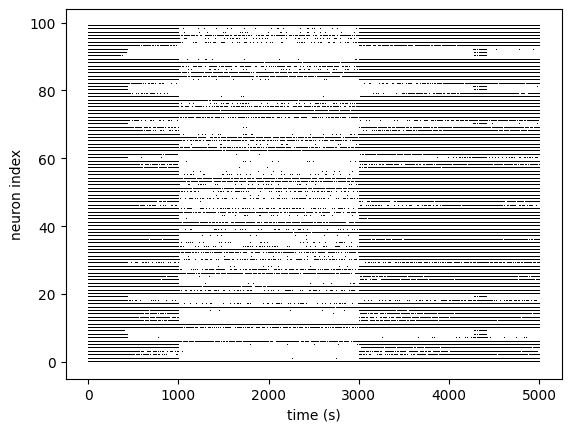

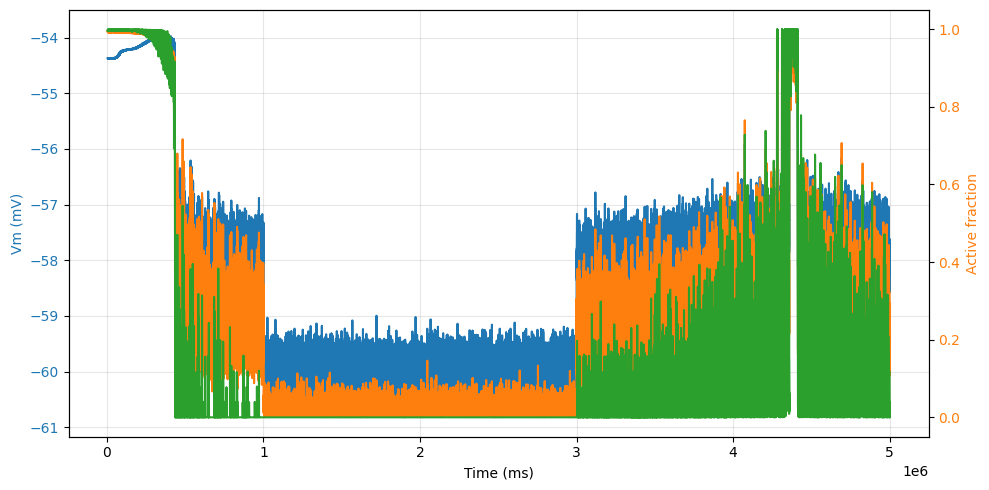

In [2]:
start_scope()
defaultclock.dt = 500 * us
net = test(1,alcohol=False,show_time=5000*second,target_rate=10*Hz)

#defaultclock.dt = 250 * us
#net = test(1,alcohol=False,show_time=3600*second,target_rate=10*Hz)

V_mon = net['V_mon']  
act_mon=net['act_mon']
act_mon_I=net['act_mon_I']
spE = net['sp_exc']
spI = net['sp_inh']
plot_raster(spE.i, spE.t, time_unit=second, marker=',', color='k')

step=0.01 #0.001
t_end=V_mon.t[-1]/second
t_grid = np.arange(0.0, t_end + step, step)
#t_grid = np.asarray(V_mon.t/second, dtype=float)
rE  = kuramoto_r_from_spikes(spE, N_E, t_grid)
rI  = kuramoto_r_from_spikes(spI, N_I, t_grid)


fig, ax1 = plt.subplots(figsize=(10,5))

# first trace: Vm
ax1.plot(V_mon.t[500:]/ms, V_mon.vm_pop[0,500:]/mV, color='tab:blue', label='Vm mean')
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Vm (mV)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, alpha=0.3)

# second y-axis for active fraction
ax2 = ax1.twinx()
ax2.plot(act_mon.t[500:]/ms, act_mon.frac_act[0,500:], color='tab:orange', label='Active fraction')
ax2.plot(act_mon_I.t[500:]/ms, act_mon_I.frac_act[0,500:], color='tab:green', label='Active fraction')
ax2.set_ylabel('Active fraction', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

fig.tight_layout()
plt.show()

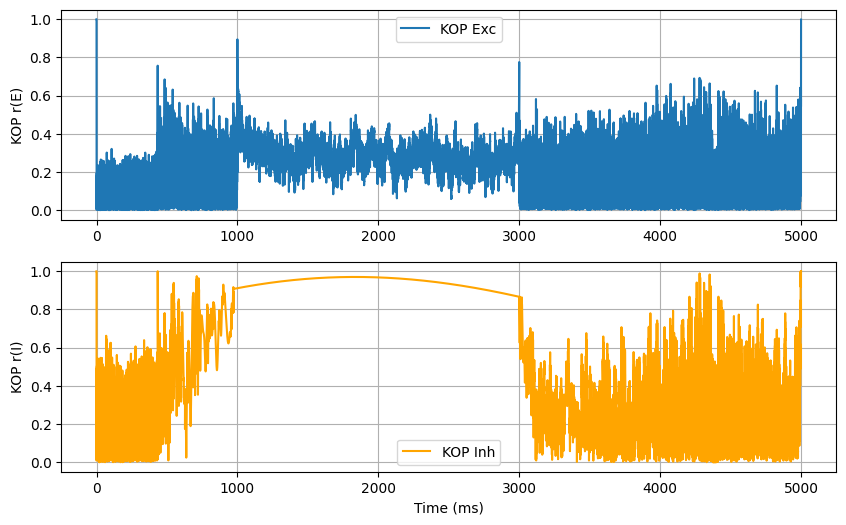

In [3]:
plt.figure(figsize=(10,6))

plt.subplot(2,1,1)
plt.plot(t_grid, rE, label='KOP Exc')
plt.ylabel(f'KOP r(E)')
plt.legend()
plt.grid(True)

plt.subplot(2,1,2)
plt.plot(t_grid, rI, color='orange', label='KOP Inh')
plt.xlabel('Time (ms)')
plt.ylabel(f'KOP r(I)')
plt.legend()
plt.grid(True)

smaller tcst average hsp

Output neuron 0 is connected to input neurons: 0
Output neuron 0 is connected to input neurons: 12
Output neuron 0 is connected to input neurons: 24
Output neuron 0 is connected to input neurons: 1
Output neuron 0 is connected to input neurons: 13
Output neuron 0 is connected to input neurons: 25
Output neuron 0 is connected to input neurons: 2
Output neuron 0 is connected to input neurons: 14
Output neuron 0 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 1
Output neuron 1 is connected to input neurons: 13
Output neuron 1 is connected to input neurons: 25
Output neuron 1 is connected to input neurons: 2
Output neuron 1 is connected to input neurons: 14
Output neuron 1 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 3
Output neuron 1 is connected to input neurons: 15
Output neuron 1 is connected to input neurons: 27
Output neuron 2 is connected to input neurons: 2
Output neuron 2 is connected to input neurons: 14
Output 

INFO:root:building '_cython_magic_780007d6804a9492116bcc6908c86a15' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_780007d6804a9492116bcc6908c86a15.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_780007d6804a9492116bcc6908c86a15.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_780007d6804a9492116bcc6908c86a15.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s
Loading data/train_images_diag/img_000.npy (12, 12)
Tested image 1/1


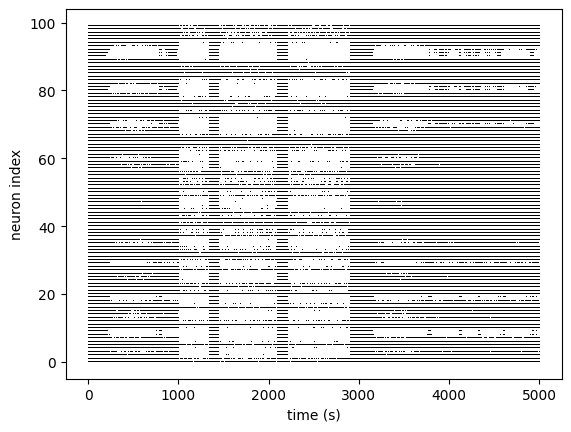

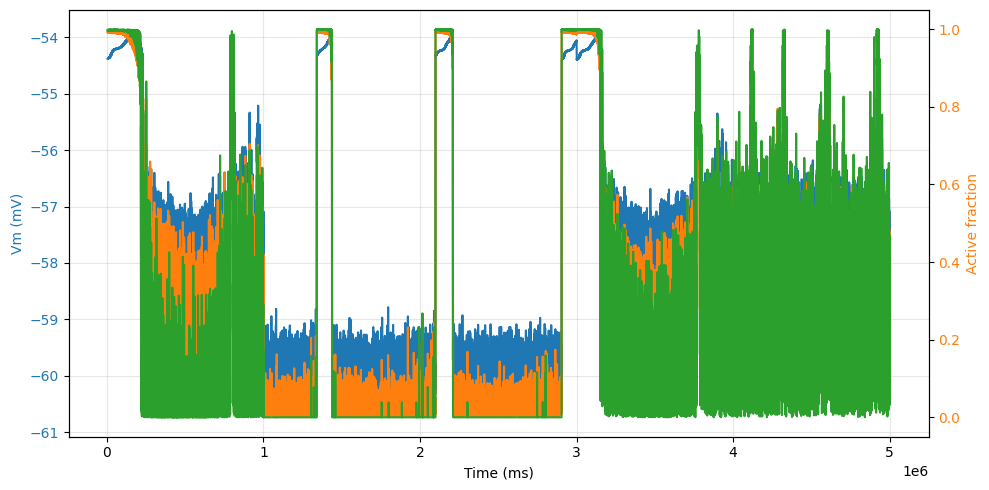

In [30]:
start_scope()
defaultclock.dt = 500 * us
net = test(1,alcohol=False,show_time=5000*second,target_rate=10*Hz)

#defaultclock.dt = 250 * us
#net = test(1,alcohol=False,show_time=3600*second,target_rate=10*Hz)

V_mon = net['V_mon']  
act_mon=net['act_mon']
act_mon_I=net['act_mon_I']
spE = net['sp_exc']
spI = net['sp_inh']
plot_raster(spE.i, spE.t, time_unit=second, marker=',', color='k')

step=0.01 #0.001
t_end=V_mon.t[-1]/second
t_grid = np.arange(0.0, t_end + step, step)
#t_grid = np.asarray(V_mon.t/second, dtype=float)
rE  = kuramoto_r_from_spikes(spE, N_E, t_grid)
rI  = kuramoto_r_from_spikes(spI, N_I, t_grid)


fig, ax1 = plt.subplots(figsize=(10,5))

# first trace: Vm
ax1.plot(V_mon.t[500:]/ms, V_mon.vm_pop[0,500:]/mV, color='tab:blue', label='Vm mean')
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Vm (mV)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, alpha=0.3)

# second y-axis for active fraction
ax2 = ax1.twinx()
ax2.plot(act_mon.t[500:]/ms, act_mon.frac_act[0,500:], color='tab:orange', label='Active fraction')
ax2.plot(act_mon_I.t[500:]/ms, act_mon_I.frac_act[0,500:], color='tab:green', label='Active fraction')
ax2.set_ylabel('Active fraction', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

fig.tight_layout()
plt.show()

same hsp tcst but slower insertion/internalization tcst

Output neuron 0 is connected to input neurons: 0
Output neuron 0 is connected to input neurons: 12
Output neuron 0 is connected to input neurons: 24
Output neuron 0 is connected to input neurons: 1
Output neuron 0 is connected to input neurons: 13
Output neuron 0 is connected to input neurons: 25
Output neuron 0 is connected to input neurons: 2
Output neuron 0 is connected to input neurons: 14
Output neuron 0 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 1
Output neuron 1 is connected to input neurons: 13
Output neuron 1 is connected to input neurons: 25
Output neuron 1 is connected to input neurons: 2
Output neuron 1 is connected to input neurons: 14
Output neuron 1 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 3
Output neuron 1 is connected to input neurons: 15
Output neuron 1 is connected to input neurons: 27
Output neuron 2 is connected to input neurons: 2
Output neuron 2 is connected to input neurons: 14
Output 

INFO:root:building '_cython_magic_30107a21a0d4706fa56f7a83ff1190a3' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_30107a21a0d4706fa56f7a83ff1190a3.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_30107a21a0d4706fa56f7a83ff1190a3.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_30107a21a0d4706fa56f7a83ff1190a3.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s
Loading data/train_images_diag/img_000.npy (12, 12)
Tested image 1/1


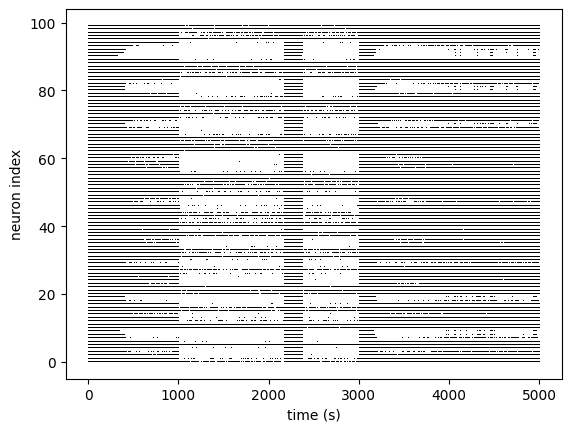

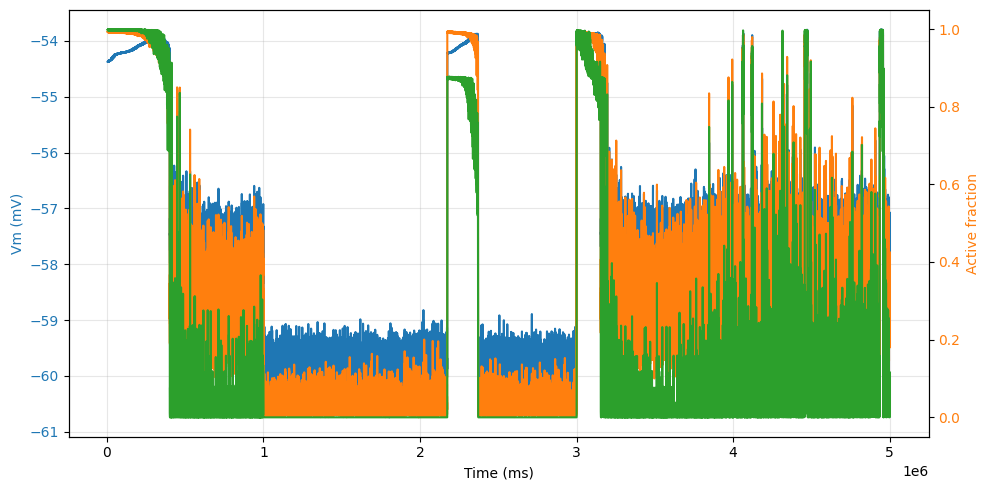

In [34]:
start_scope()
defaultclock.dt = 500 * us
net = test(1,alcohol=False,show_time=5000*second,target_rate=10*Hz)

#defaultclock.dt = 250 * us
#net = test(1,alcohol=False,show_time=3600*second,target_rate=10*Hz)

V_mon = net['V_mon']  
act_mon=net['act_mon']
act_mon_I=net['act_mon_I']
spE = net['sp_exc']
spI = net['sp_inh']
plot_raster(spE.i, spE.t, time_unit=second, marker=',', color='k')

step=0.01 #0.001
t_end=V_mon.t[-1]/second
t_grid = np.arange(0.0, t_end + step, step)
#t_grid = np.asarray(V_mon.t/second, dtype=float)
rE  = kuramoto_r_from_spikes(spE, N_E, t_grid)
rI  = kuramoto_r_from_spikes(spI, N_I, t_grid)


fig, ax1 = plt.subplots(figsize=(10,5))

# first trace: Vm
ax1.plot(V_mon.t[500:]/ms, V_mon.vm_pop[0,500:]/mV, color='tab:blue', label='Vm mean')
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Vm (mV)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, alpha=0.3)

# second y-axis for active fraction
ax2 = ax1.twinx()
ax2.plot(act_mon.t[500:]/ms, act_mon.frac_act[0,500:], color='tab:orange', label='Active fraction')
ax2.plot(act_mon_I.t[500:]/ms, act_mon_I.frac_act[0,500:], color='tab:green', label='Active fraction')
ax2.set_ylabel('Active fraction', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

fig.tight_layout()
plt.show()

20Hz

Output neuron 0 is connected to input neurons: 0
Output neuron 0 is connected to input neurons: 12
Output neuron 0 is connected to input neurons: 24
Output neuron 0 is connected to input neurons: 1
Output neuron 0 is connected to input neurons: 13
Output neuron 0 is connected to input neurons: 25
Output neuron 0 is connected to input neurons: 2
Output neuron 0 is connected to input neurons: 14
Output neuron 0 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 1
Output neuron 1 is connected to input neurons: 13
Output neuron 1 is connected to input neurons: 25
Output neuron 1 is connected to input neurons: 2
Output neuron 1 is connected to input neurons: 14
Output neuron 1 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 3
Output neuron 1 is connected to input neurons: 15
Output neuron 1 is connected to input neurons: 27
Output neuron 2 is connected to input neurons: 2
Output neuron 2 is connected to input neurons: 14
Output 

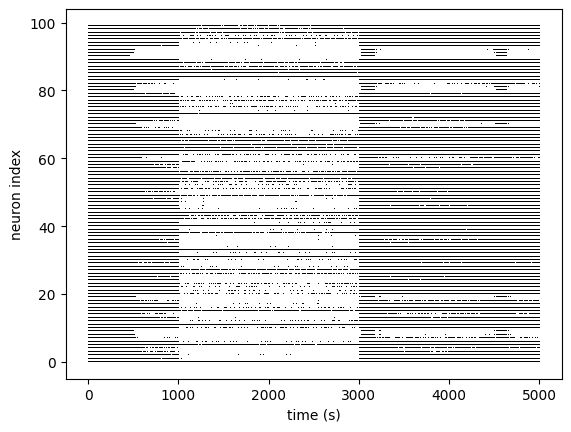

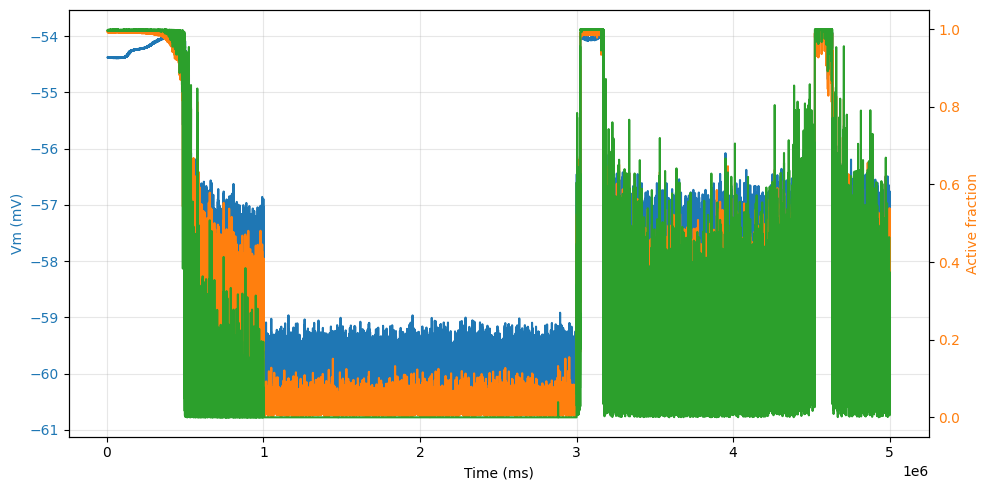

In [9]:
start_scope()
defaultclock.dt = 500 * us
net = test(1,alcohol=False,show_time=5000*second,target_rate=10*Hz)

#defaultclock.dt = 250 * us
#net = test(1,alcohol=False,show_time=3600*second,target_rate=10*Hz)

V_mon = net['V_mon']  
act_mon=net['act_mon']
act_mon_I=net['act_mon_I']
spE = net['sp_exc']
spI = net['sp_inh']
plot_raster(spE.i, spE.t, time_unit=second, marker=',', color='k')

step=0.01 #0.001
t_end=V_mon.t[-1]/second
t_grid = np.arange(0.0, t_end + step, step)
#t_grid = np.asarray(V_mon.t/second, dtype=float)
rE  = kuramoto_r_from_spikes(spE, N_E, t_grid)
rI  = kuramoto_r_from_spikes(spI, N_I, t_grid)


fig, ax1 = plt.subplots(figsize=(10,5))

# first trace: Vm
ax1.plot(V_mon.t[500:]/ms, V_mon.vm_pop[0,500:]/mV, color='tab:blue', label='Vm mean')
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Vm (mV)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, alpha=0.3)

# second y-axis for active fraction
ax2 = ax1.twinx()
ax2.plot(act_mon.t[500:]/ms, act_mon.frac_act[0,500:], color='tab:orange', label='Active fraction')
ax2.plot(act_mon_I.t[500:]/ms, act_mon_I.frac_act[0,500:], color='tab:green', label='Active fraction')
ax2.set_ylabel('Active fraction', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

fig.tight_layout()
plt.show()

10hz shorter tau hsp

Output neuron 0 is connected to input neurons: 0
Output neuron 0 is connected to input neurons: 12
Output neuron 0 is connected to input neurons: 24
Output neuron 0 is connected to input neurons: 1
Output neuron 0 is connected to input neurons: 13
Output neuron 0 is connected to input neurons: 25
Output neuron 0 is connected to input neurons: 2
Output neuron 0 is connected to input neurons: 14
Output neuron 0 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 1
Output neuron 1 is connected to input neurons: 13
Output neuron 1 is connected to input neurons: 25
Output neuron 1 is connected to input neurons: 2
Output neuron 1 is connected to input neurons: 14
Output neuron 1 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 3
Output neuron 1 is connected to input neurons: 15
Output neuron 1 is connected to input neurons: 27
Output neuron 2 is connected to input neurons: 2
Output neuron 2 is connected to input neurons: 14
Output 

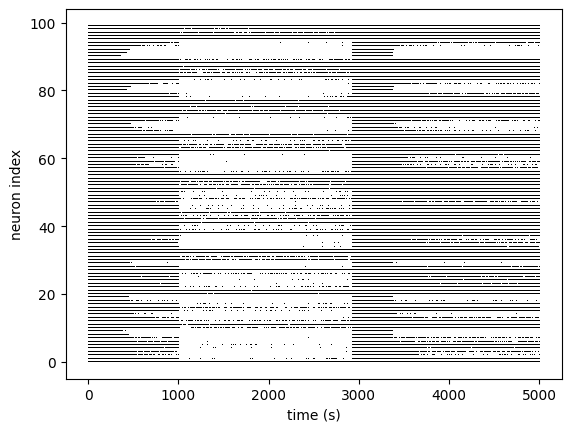

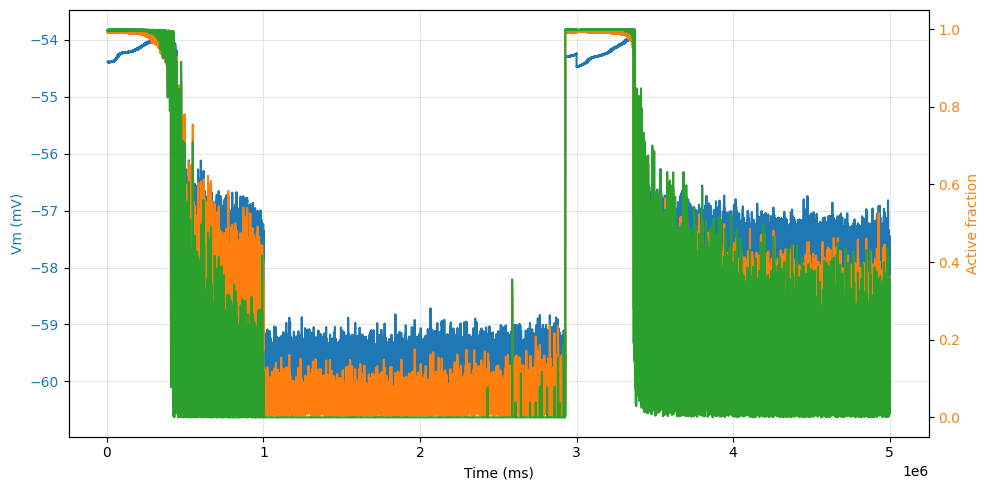

In [11]:
start_scope()
defaultclock.dt = 500 * us
net = test(1,alcohol=False,show_time=5000*second,target_rate=10*Hz)

#defaultclock.dt = 250 * us
#net = test(1,alcohol=False,show_time=3600*second,target_rate=10*Hz)

V_mon = net['V_mon']  
act_mon=net['act_mon']
act_mon_I=net['act_mon_I']
spE = net['sp_exc']
spI = net['sp_inh']
plot_raster(spE.i, spE.t, time_unit=second, marker=',', color='k')

step=0.01 #0.001
t_end=V_mon.t[-1]/second
t_grid = np.arange(0.0, t_end + step, step)
#t_grid = np.asarray(V_mon.t/second, dtype=float)
rE  = kuramoto_r_from_spikes(spE, N_E, t_grid)
rI  = kuramoto_r_from_spikes(spI, N_I, t_grid)


fig, ax1 = plt.subplots(figsize=(10,5))

# first trace: Vm
ax1.plot(V_mon.t[500:]/ms, V_mon.vm_pop[0,500:]/mV, color='tab:blue', label='Vm mean')
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Vm (mV)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, alpha=0.3)

# second y-axis for active fraction
ax2 = ax1.twinx()
ax2.plot(act_mon.t[500:]/ms, act_mon.frac_act[0,500:], color='tab:orange', label='Active fraction')
ax2.plot(act_mon_I.t[500:]/ms, act_mon_I.frac_act[0,500:], color='tab:green', label='Active fraction')
ax2.set_ylabel('Active fraction', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

fig.tight_layout()
plt.show()

Output neuron 0 is connected to input neurons: 0
Output neuron 0 is connected to input neurons: 12
Output neuron 0 is connected to input neurons: 24
Output neuron 0 is connected to input neurons: 1
Output neuron 0 is connected to input neurons: 13
Output neuron 0 is connected to input neurons: 25
Output neuron 0 is connected to input neurons: 2
Output neuron 0 is connected to input neurons: 14
Output neuron 0 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 1
Output neuron 1 is connected to input neurons: 13
Output neuron 1 is connected to input neurons: 25
Output neuron 1 is connected to input neurons: 2
Output neuron 1 is connected to input neurons: 14
Output neuron 1 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 3
Output neuron 1 is connected to input neurons: 15
Output neuron 1 is connected to input neurons: 27
Output neuron 2 is connected to input neurons: 2
Output neuron 2 is connected to input neurons: 14
Output 

WARNING    /home/vincent/bmnn/lib/python3.12/site-packages/brian2tools/plotting/data.py:59: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "." (-> marker='.'). The keyword argument will take precedence.
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)
 [py.warnings]
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)



Tested image 1/1


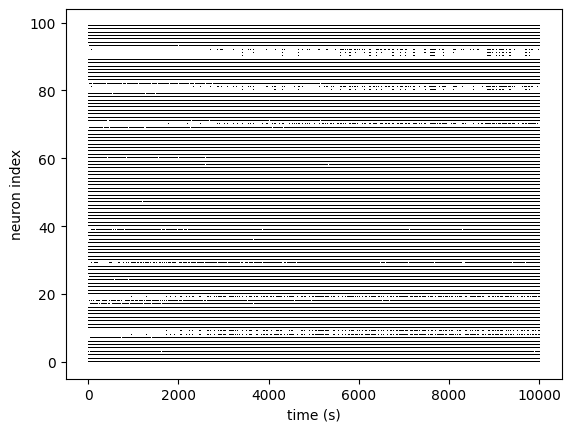

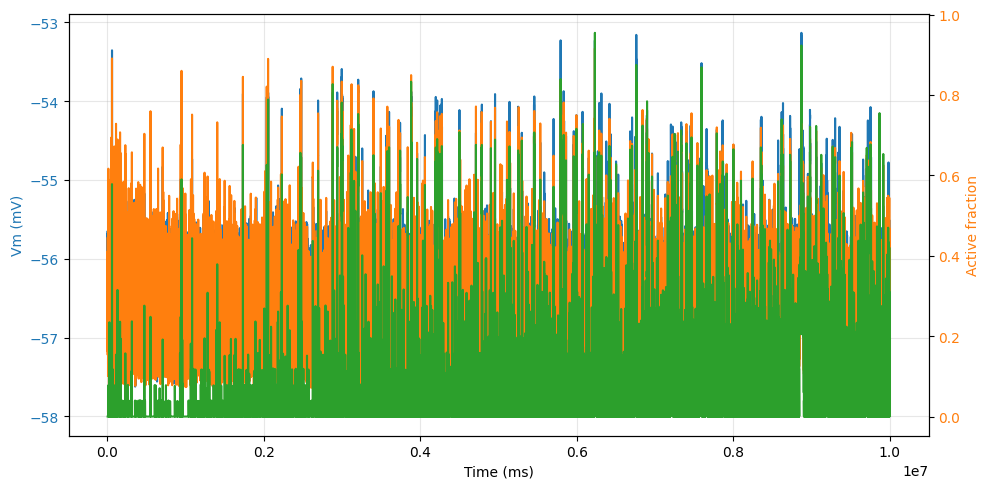

In [ ]:
start_scope()
defaultclock.dt = 500 * us
net = test(1,alcohol=False,show_time=20000*second,target_rate=10*Hz)

#defaultclock.dt = 250 * us
#net = test(1,alcohol=False,show_time=3600*second,target_rate=10*Hz)

V_mon = net['V_mon']  
act_mon=net['act_mon']
act_mon_I=net['act_mon_I']
spE = net['sp_exc']
spI = net['sp_inh']
plot_raster(spE.i, spE.t, time_unit=second, marker=',', color='k')

step=0.01 #0.001
t_end=V_mon.t[-1]/second
t_grid = np.arange(0.0, t_end + step, step)
#t_grid = np.asarray(V_mon.t/second, dtype=float)
rE  = kuramoto_r_from_spikes(spE, N_E, t_grid)
rI  = kuramoto_r_from_spikes(spI, N_I, t_grid)


fig, ax1 = plt.subplots(figsize=(10,5))

# first trace: Vm
ax1.plot(V_mon.t[500:]/ms, V_mon.vm_pop[0,500:]/mV, color='tab:blue', label='Vm mean')
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Vm (mV)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, alpha=0.3)

# second y-axis for active fraction
ax2 = ax1.twinx()
ax2.plot(act_mon.t[500:]/ms, act_mon.frac_act[0,500:], color='tab:orange', label='Active fraction')
ax2.plot(act_mon_I.t[500:]/ms, act_mon_I.frac_act[0,500:], color='tab:green', label='Active fraction')
ax2.set_ylabel('Active fraction', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

fig.tight_layout()
plt.show()

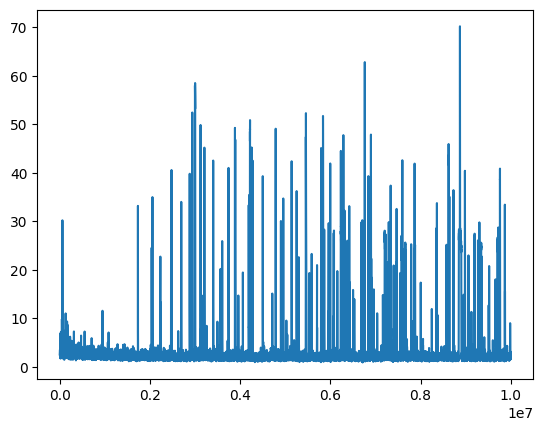

In [20]:
r_est = net['rate_pop_mon_E']  
plot(r_est.t[500:]/ms, r_est.r_pop_E[0,500:]/Hz, color='tab:blue', label='rate')


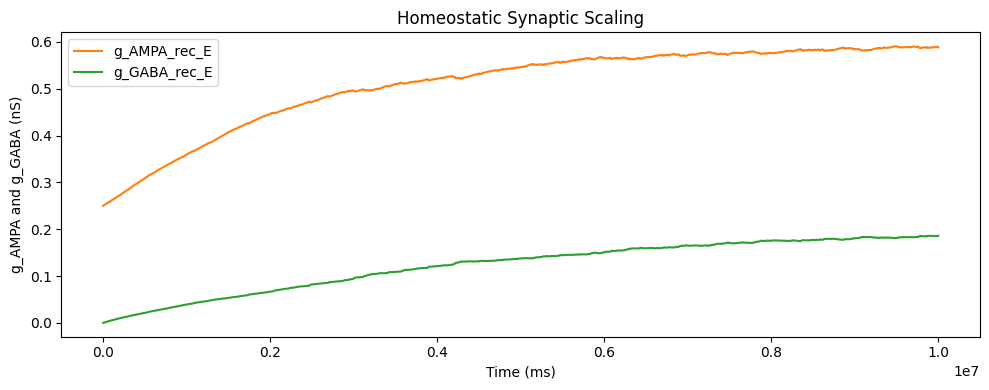

In [21]:
gAMPA_mon_E=net['g_AMPA_E_hsp']
gGABA_mon_E=net['g_GABA_E_hsp']

plt.figure(figsize=(10, 4))
plt.plot(gAMPA_mon_E.t/ms, gAMPA_mon_E.g_AMPA_E_hsp[58], label='g_AMPA_rec_E',color='tab:orange')
plt.plot(gGABA_mon_E.t/ms, gGABA_mon_E.g_GABA_E_hsp[58], label='g_GABA_rec_E',color='tab:green')
plt.xlabel('Time (ms)')
plt.ylabel('g_AMPA and g_GABA (nS)')
plt.title('Homeostatic Synaptic Scaling')
plt.legend()
plt.tight_layout()



Output neuron 0 is connected to input neurons: 0
Output neuron 0 is connected to input neurons: 12
Output neuron 0 is connected to input neurons: 24
Output neuron 0 is connected to input neurons: 1
Output neuron 0 is connected to input neurons: 13
Output neuron 0 is connected to input neurons: 25
Output neuron 0 is connected to input neurons: 2
Output neuron 0 is connected to input neurons: 14
Output neuron 0 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 1
Output neuron 1 is connected to input neurons: 13
Output neuron 1 is connected to input neurons: 25
Output neuron 1 is connected to input neurons: 2
Output neuron 1 is connected to input neurons: 14
Output neuron 1 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 3
Output neuron 1 is connected to input neurons: 15
Output neuron 1 is connected to input neurons: 27
Output neuron 2 is connected to input neurons: 2
Output neuron 2 is connected to input neurons: 14
Output 

INFO:root:building '_cython_magic_434617c666178e7566b723f10b7abae1' extension
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -I/home/vincent/bmnn/include -I/home/vincent/bmnn/lib/python3.12/site-packages/numpy/core/include -I/home/vincent/bmnn/lib/python3.12/site-packages/brian2/synapses -I/home/vincent/bmnn/include -I/usr/include/python3.12 -c /home/vincent/.cython/brian_extensions/_cython_magic_434617c666178e7566b723f10b7abae1.cpp -o /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_434617c666178e7566b723f10b7abae1.o -w -O3 -ffast-math -fno-finite-math-only -march=native -std=c++11
INFO:root:x86_64-linux-gnu-g++ -shared -Wl,-O1 -Wl,-Bsymbolic-functions -Wl,-Bsymbolic-functions -Wl,-z,relro -g -fwrapv -O2 /home/vincent/.cython/brian_extensions/home/vincent/.cython/brian_extensions/_cython_magic_434617c666178e7566b723f10b7abae1.o -L/home/vincent/bmnn/lib -L/usr/lib/x86_64-linux-gnu -Wl,--enable-new

Starting simulation at t=0. s for a duration of 0. s
0. s (100%) simulated in < 1s


WARNING    'rates' is an internal variable of group 'inp', but also exists in the run namespace with the value array([16.71540567, 19.34177918, 20.04461621, ..., 20.03874197,
       29.29208444, 20.32258602]). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Starting simulation at t=0. s for a duration of 20. ks
105.055 s (0%) simulated in 10s, estimated 31m 34s remaining.
202.801 s (1%) simulated in 20s, estimated 32m 32s remaining.
0.316998 ks (1%) simulated in 30s, estimated 31m 3s remaining.
0.398277 ks (1%) simulated in 40s, estimated 32m 49s remaining.
0.473051 ks (2%) simulated in 50s, estimated 34m 24s remaining.
0.563706 ks (2%) simulated in 1m 0s, estimated 34m 29s remaining.
0.631789 ks (3%) simulated in 1m 10s, estimated 35m 46s remaining.
0.713577 ks (3%) simulated in 1m 20s, estimated 36m 2s remaining.
0.834296 ks (4%) simulated in 1m 30s, estimated 34m 28s remaining.
0.934772 ks (4%) simulated in 1m 40s, estimated 34m 0s remaining.
1.034343 ks (5%) simulated in 1m 50s, estimated 33m 37s remaining.
1.147159 ks (5%) simulated in 2m 0s, estimated 32m 52s remaining.
1.244292 ks (6%) simulated in 2m 10s, estimated 32m 40s remaining.
1.34399 ks (6%) simulated in 2m 20s, estimated 32m 23s remaining.
1.461164 ks (7%) simulated in 2m

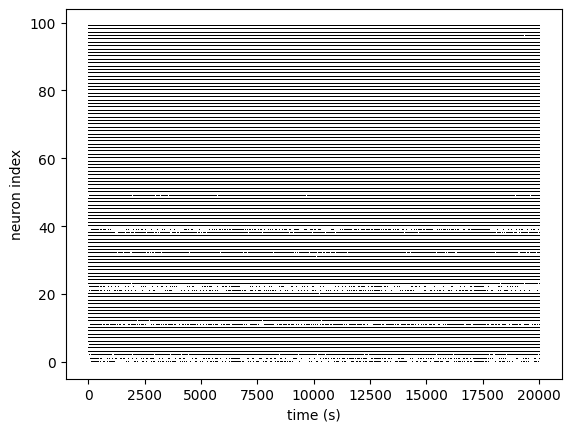

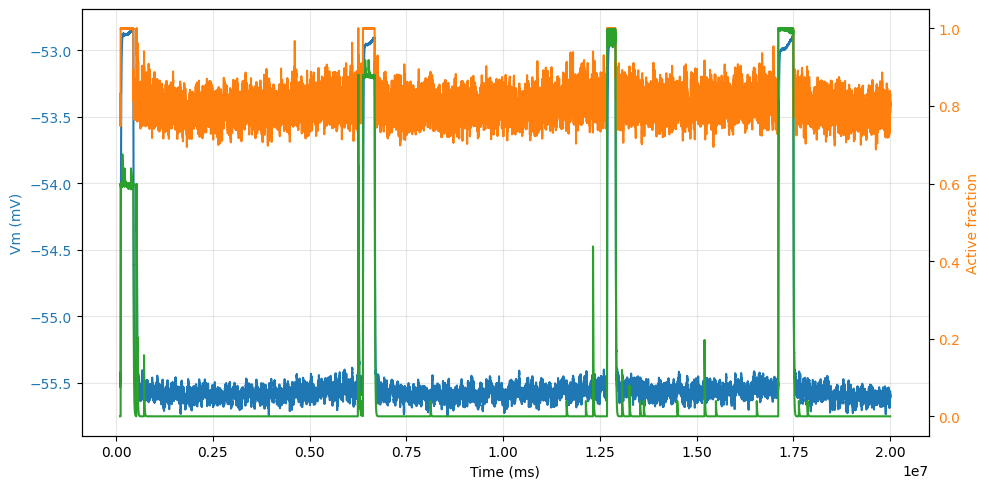

In [59]:
start_scope()
defaultclock.dt = 1000 * us
net = test(1,alcohol=False,show_time=20000*second,target_rate=10*Hz)

#defaultclock.dt = 250 * us
#net = test(1,alcohol=False,show_time=3600*second,target_rate=10*Hz)

V_mon = net['V_mon']  
act_mon=net['act_mon']
act_mon_I=net['act_mon_I']
spE = net['sp_exc']
spI = net['sp_inh']
plot_raster(spE.i, spE.t, time_unit=second, marker=',', color='k')

step=0.1 #0.001
t_end=V_mon.t[-1]/second
t_grid = np.arange(0.0, t_end + step, step)
#t_grid = np.asarray(V_mon.t/second, dtype=float)
rE  = kuramoto_r_from_spikes(spE, N_E, t_grid)
rI  = kuramoto_r_from_spikes(spI, N_I, t_grid)


fig, ax1 = plt.subplots(figsize=(10,5))

ax1.plot(V_mon.t[500:]/ms, V_mon.vm_pop[0,500:]/mV, color='tab:blue', label='Vm mean')
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Vm (mV)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(act_mon.t[500:]/ms, act_mon.frac_act[0,500:], color='tab:orange', label='Active fraction')
ax2.plot(act_mon_I.t[500:]/ms, act_mon_I.frac_act[0,500:], color='tab:green', label='Active fraction')
ax2.set_ylabel('Active fraction', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

fig.tight_layout()
plt.show()

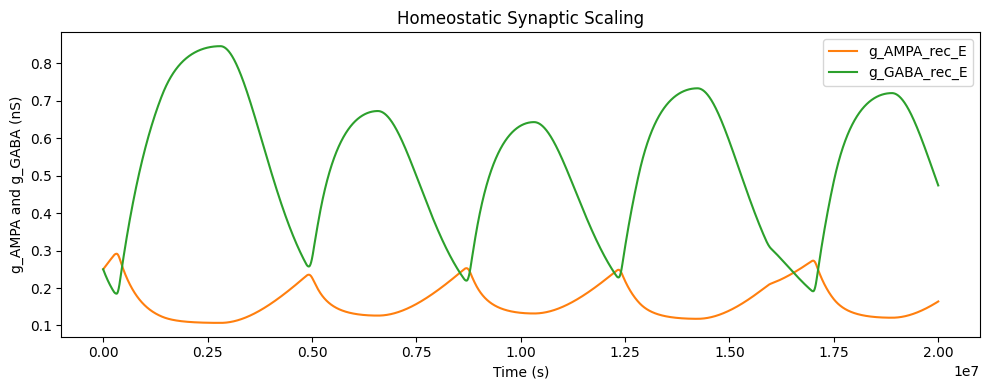

In [57]:
gAMPA_mon_E=net['g_AMPA_E_hsp']
gGABA_mon_E=net['g_GABA_E_hsp']

plt.figure(figsize=(10, 4))
plt.plot(gAMPA_mon_E.t/ms, gAMPA_mon_E.g_AMPA_E_hsp[35], label='g_AMPA_rec_E',color='tab:orange')
plt.plot(gGABA_mon_E.t/ms, gGABA_mon_E.g_GABA_E_hsp[35], label='g_GABA_rec_E',color='tab:green')
plt.xlabel('Time (s)')
plt.ylabel('g_AMPA and g_GABA (nS)')
plt.title('Homeostatic Synaptic Scaling')
plt.legend()
plt.tight_layout()



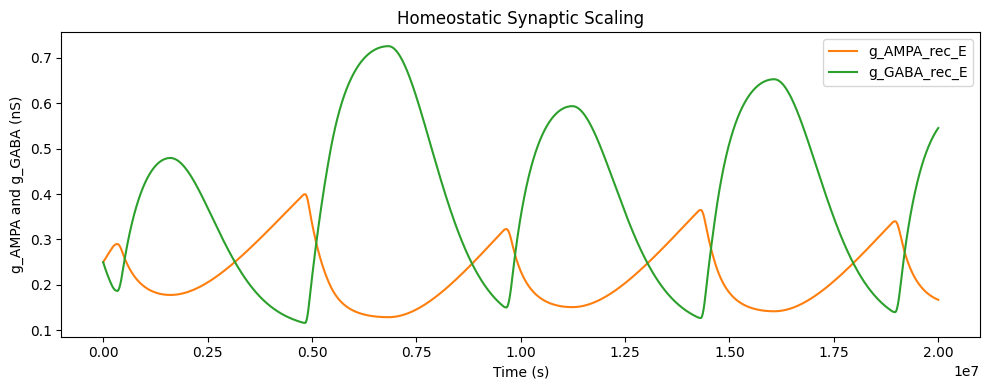

In [51]:
gAMPA_mon_E=net['g_AMPA_E_hsp']
gGABA_mon_E=net['g_GABA_E_hsp']

plt.figure(figsize=(10, 4))
plt.plot(gAMPA_mon_E.t/ms, gAMPA_mon_E.g_AMPA_E_hsp[50], label='g_AMPA_rec_E',color='tab:orange')
plt.plot(gGABA_mon_E.t/ms, gGABA_mon_E.g_GABA_E_hsp[50], label='g_GABA_rec_E',color='tab:green')
plt.xlabel('Time (s)')
plt.ylabel('g_AMPA and g_GABA (nS)')
plt.title('Homeostatic Synaptic Scaling')
plt.legend()
plt.tight_layout()

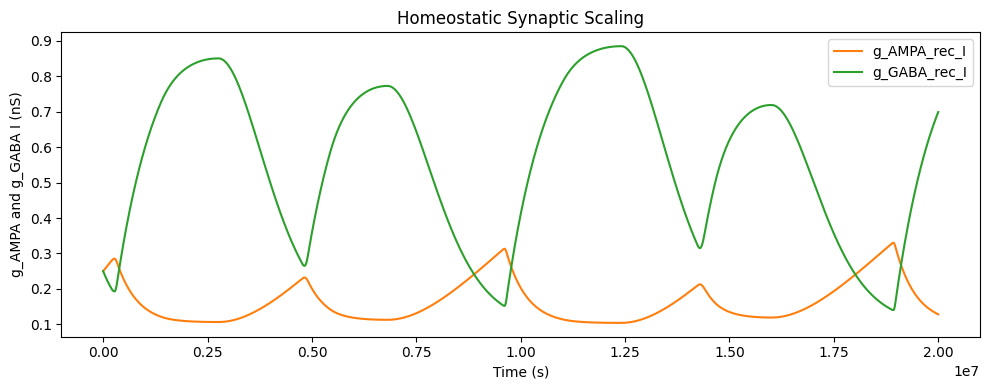

In [52]:
gAMPA_mon_I=net['g_AMPA_I_hsp']
gGABA_mon_I=net['g_GABA_I_hsp']

plt.figure(figsize=(10, 4))
plt.plot(gAMPA_mon_I.t/ms, gAMPA_mon_I.g_AMPA_I_hsp[6], label='g_AMPA_rec_I',color='tab:orange')
plt.plot(gGABA_mon_I.t/ms, gGABA_mon_I.g_GABA_I_hsp[6], label='g_GABA_rec_I',color='tab:green')
plt.xlabel('Time (s)')
plt.ylabel('g_AMPA and g_GABA I (nS)')
plt.title('Homeostatic Synaptic Scaling')
plt.legend()
plt.tight_layout()

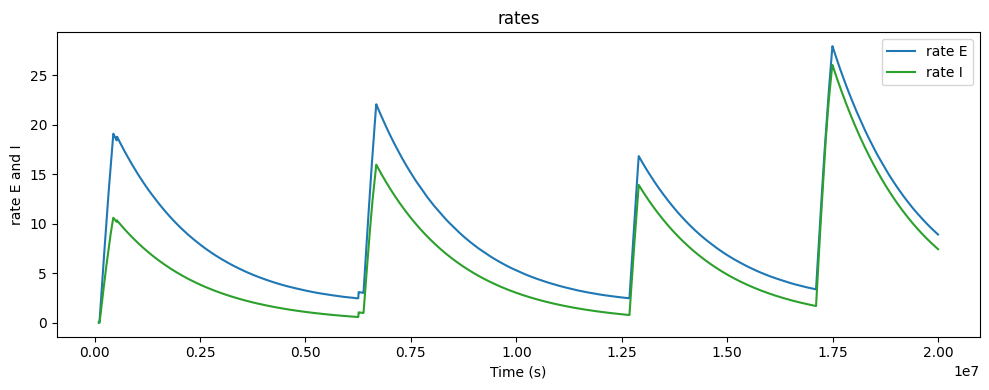

In [60]:
r_est_E = net['rate_pop_mon_E']  
r_est_I = net['rate_pop_mon_I']  

plt.figure(figsize=(10, 4))
plt.plot(r_est_E.t[500:]/ms, r_est_E.r_pop_E[0,500:]/Hz, color='tab:blue', label='rate E')
plt.plot(r_est_I.t[500:]/ms, r_est_I.r_pop_I[0,500:]/Hz, color='tab:green', label='rate I')
plt.xlabel('Time (s)')
plt.ylabel('rate E and I')
plt.title('rates')
plt.legend()
plt.tight_layout()


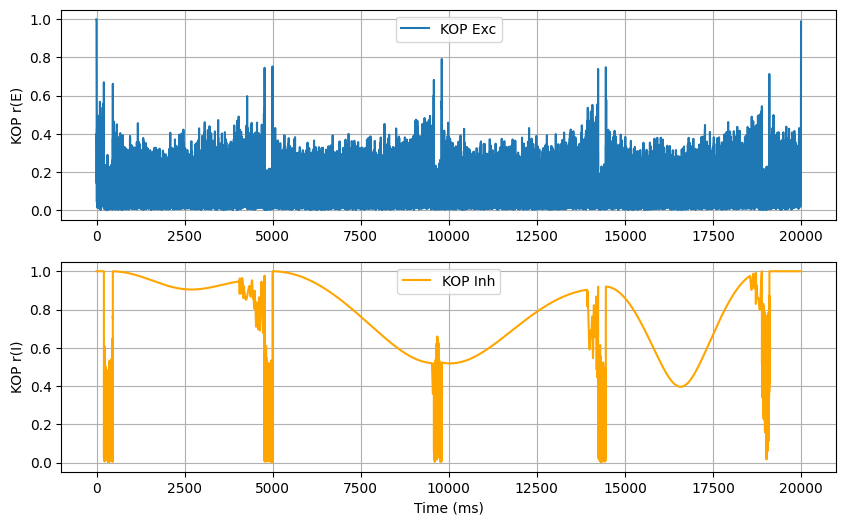

In [54]:
plt.figure(figsize=(10,6))

plt.subplot(2,1,1)
plt.plot(t_grid, rE, label='KOP Exc')
plt.ylabel(f'KOP r(E)')
plt.legend()
plt.grid(True)

plt.subplot(2,1,2)
plt.plot(t_grid, rI, color='orange', label='KOP Inh')
plt.xlabel('Time (ms)')
plt.ylabel(f'KOP r(I)')
plt.legend()
plt.grid(True)

Back to long tc for hsp

INFO:root:creating /tmp/brian_flag_test_nlqjhvh6/tmp
INFO:root:creating /tmp/brian_flag_test_nlqjhvh6/tmp/brian_flag_test_nlqjhvh6
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_nlqjhvh6/flag_test.cpp -o /tmp/brian_flag_test_nlqjhvh6/tmp/brian_flag_test_nlqjhvh6/flag_test.o -w
INFO:root:creating /tmp/brian_flag_test_4ipjb8fp/tmp
INFO:root:creating /tmp/brian_flag_test_4ipjb8fp/tmp/brian_flag_test_4ipjb8fp
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_4ipjb8fp/flag_test.cpp -o /tmp/brian_flag_test_4ipjb8fp/tmp/brian_flag_test_4ipjb8fp/flag_test.o -O3
INFO:root:creating /tmp/brian_flag_test_ydj45k6e/tmp
INFO:root:creating /tmp/brian_flag_test_ydj45k6e/tmp/brian_flag_test_ydj45k6e
INFO:root:x86_64-linux-gnu-gcc -fno-strict-overflow -Wsign-compare -DNDEBUG -g -O2 -Wall -fPIC -c /tmp/brian_flag_test_ydj45k6e/flag_test.cpp -o /tmp/brian_flag_test_yd

Output neuron 0 is connected to input neurons: 0
Output neuron 0 is connected to input neurons: 12
Output neuron 0 is connected to input neurons: 24
Output neuron 0 is connected to input neurons: 1
Output neuron 0 is connected to input neurons: 13
Output neuron 0 is connected to input neurons: 25
Output neuron 0 is connected to input neurons: 2
Output neuron 0 is connected to input neurons: 14
Output neuron 0 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 1
Output neuron 1 is connected to input neurons: 13
Output neuron 1 is connected to input neurons: 25
Output neuron 1 is connected to input neurons: 2
Output neuron 1 is connected to input neurons: 14
Output neuron 1 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 3
Output neuron 1 is connected to input neurons: 15
Output neuron 1 is connected to input neurons: 27
Output neuron 2 is connected to input neurons: 2
Output neuron 2 is connected to input neurons: 14
Output 

WARNING    /home/vincent/bmnn/lib/python3.12/site-packages/brian2tools/plotting/data.py:59: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "." (-> marker='.'). The keyword argument will take precedence.
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)
 [py.warnings]
  axes.plot(spike_times/time_unit, spike_indices, '.', **kwds)



Tested image 1/1


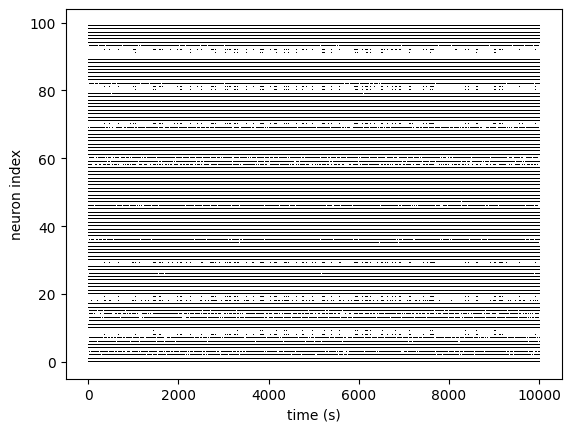

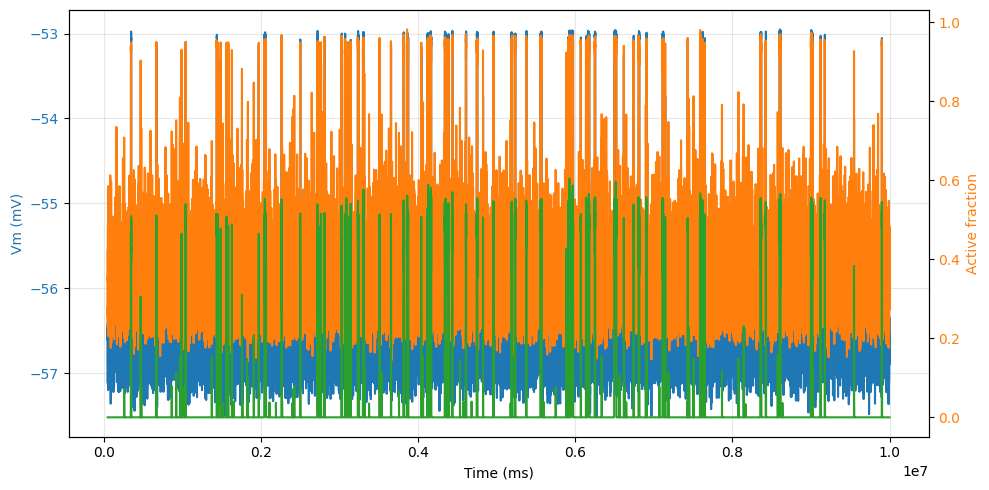

In [2]:
start_scope()
defaultclock.dt = 1000 * us
net = test(1,alcohol=False,show_time=10000*second,target_rate=10*Hz)

#defaultclock.dt = 250 * us
#net = test(1,alcohol=False,show_time=3600*second,target_rate=10*Hz)

V_mon = net['V_mon']  
act_mon=net['act_mon']
act_mon_I=net['act_mon_I']
spE = net['sp_exc']
spI = net['sp_inh']
plot_raster(spE.i, spE.t, time_unit=second, marker=',', color='k')

step=0.01 #0.001
t_end=V_mon.t[-1]/second
t_grid = np.arange(0.0, t_end + step, step)
#t_grid = np.asarray(V_mon.t/second, dtype=float)
# rE  = kuramoto_r_from_spikes(spE, N_E, t_grid)
# rI  = kuramoto_r_from_spikes(spI, N_I, t_grid)


fig, ax1 = plt.subplots(figsize=(10,5))

# first trace: Vm
ax1.plot(V_mon.t[500:]/ms, V_mon.vm_pop[0,500:]/mV, color='tab:blue', label='Vm mean')
ax1.set_xlabel('Time (ms)')
ax1.set_ylabel('Vm (mV)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, alpha=0.3)

# second y-axis for active fraction
ax2 = ax1.twinx()
ax2.plot(act_mon.t[500:]/ms, act_mon.frac_act[0,500:], color='tab:orange', label='Active fraction')
ax2.plot(act_mon_I.t[500:]/ms, act_mon_I.frac_act[0,500:], color='tab:green', label='Active fraction')
ax2.set_ylabel('Active fraction', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')

fig.tight_layout()
plt.show()

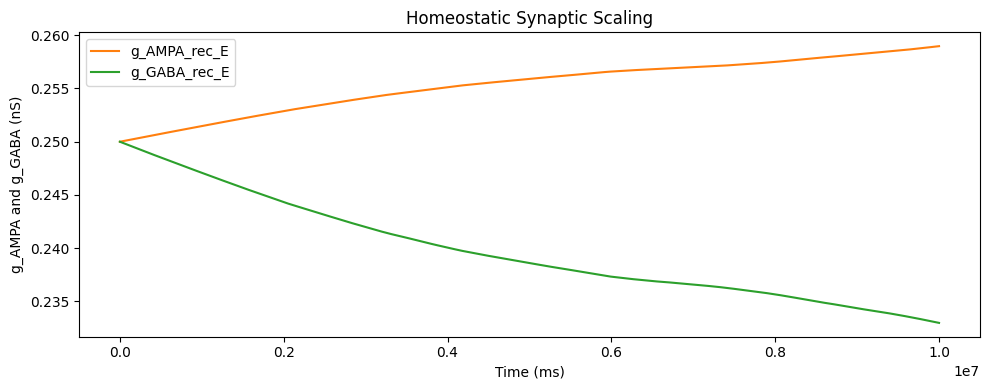

In [3]:
gAMPA_mon_E=net['g_AMPA_E_hsp']
gGABA_mon_E=net['g_GABA_E_hsp']

plt.figure(figsize=(10, 4))
plt.plot(gAMPA_mon_E.t/ms, gAMPA_mon_E.g_AMPA_E_hsp[58], label='g_AMPA_rec_E',color='tab:orange')
plt.plot(gGABA_mon_E.t/ms, gGABA_mon_E.g_GABA_E_hsp[58], label='g_GABA_rec_E',color='tab:green')
plt.xlabel('Time (ms)')
plt.ylabel('g_AMPA and g_GABA (nS)')
plt.title('Homeostatic Synaptic Scaling')
plt.legend()
plt.tight_layout()



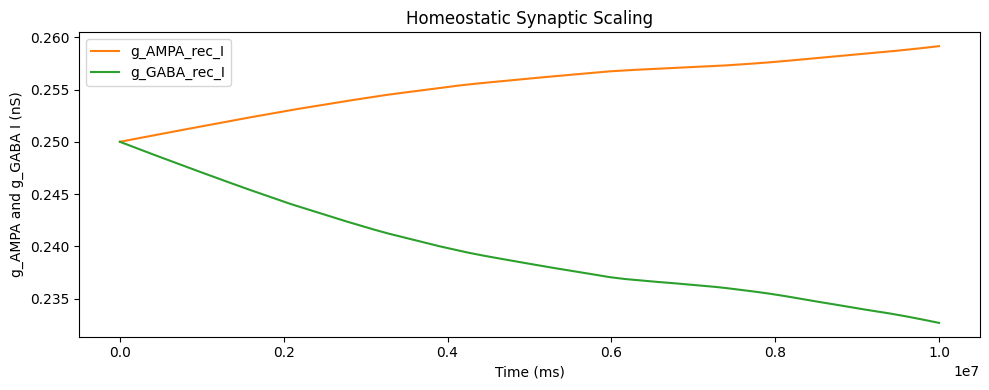

In [4]:
gAMPA_mon_I=net['g_AMPA_I_hsp']
gGABA_mon_I=net['g_GABA_I_hsp']

plt.figure(figsize=(10, 4))
plt.plot(gAMPA_mon_I.t/ms, gAMPA_mon_I.g_AMPA_I_hsp[13], label='g_AMPA_rec_I',color='tab:orange')
plt.plot(gGABA_mon_I.t/ms, gGABA_mon_I.g_GABA_I_hsp[13], label='g_GABA_rec_I',color='tab:green')
plt.xlabel('Time (ms)')
plt.ylabel('g_AMPA and g_GABA I (nS)')
plt.title('Homeostatic Synaptic Scaling')
plt.legend()
plt.tight_layout()

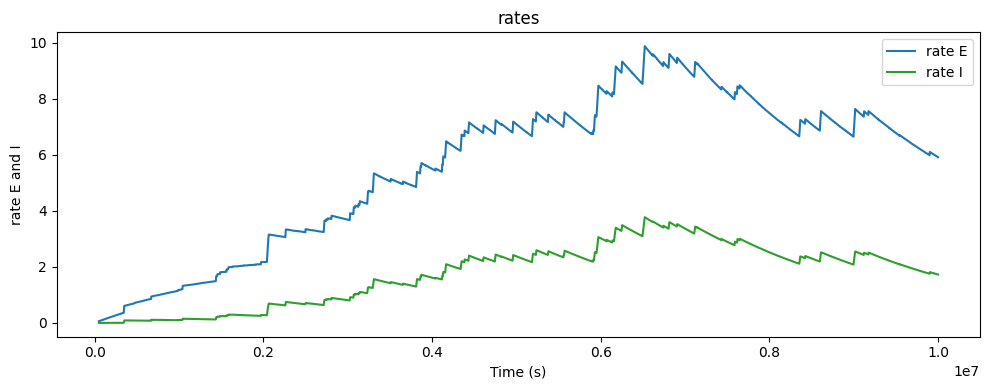

In [5]:
r_est_E = net['rate_pop_mon_E']  
r_est_I = net['rate_pop_mon_I']  

plt.figure(figsize=(10, 4))
plt.plot(r_est_E.t[500:]/ms, r_est_E.r_pop_E[0,500:]/Hz, color='tab:blue', label='rate E')
plt.plot(r_est_I.t[500:]/ms, r_est_I.r_pop_I[0,500:]/Hz, color='tab:green', label='rate I')
plt.xlabel('Time (s)')
plt.ylabel('rate E and I')
plt.title('rates')
plt.legend()
plt.tight_layout()